# Module 4 · A Real LLM: Run It, Shrink It, Adapt It, Align It
**Verse 3, second half + chorus 3 + bridge, first half · 2:13–2:57**

You built a tiny GPT in Module 2. Now download a real one (`CFG['llm']`: Qwen2.5 0.5B on `laptop`, 1.5B on `mac-max`, 7B on `cuda`; 1–15 GB on the first run, cached in `~/.cache/huggingface`) and do the things people do with LLMs in practice:

look inside it → how big models stay affordable (mixture of experts) → shrink it (32 bits → 4) → adapt it with a small patch (LoRA) → adapt it with no training at all (prompting) → align it with human preferences (RLHF, then DPO).



In [1]:
import sys; sys.path.insert(0, '.')
from blcourse import *
import matplotlib.pyplot as plt
hardware_report()



python 3.11.15 · torch 2.15.0 · arm64 · 64 GB RAM
DEVICE = 'mps'   TIER = 'laptop'   (override: BASELINE_TIER / BASELINE_DEVICE)


---

## 4.1 Meet a real LLM
Time to load `CFG['llm']`. A causal language model is the Module 2 TinyGPT with more of everything: tokens in, one score (logit) per vocabulary entry out, turned into probabilities by the softmax from §0.4. Its vocabulary has about 150,000 tokens instead of 65 characters. Here is its next-token distribution at the end of the chorus line.



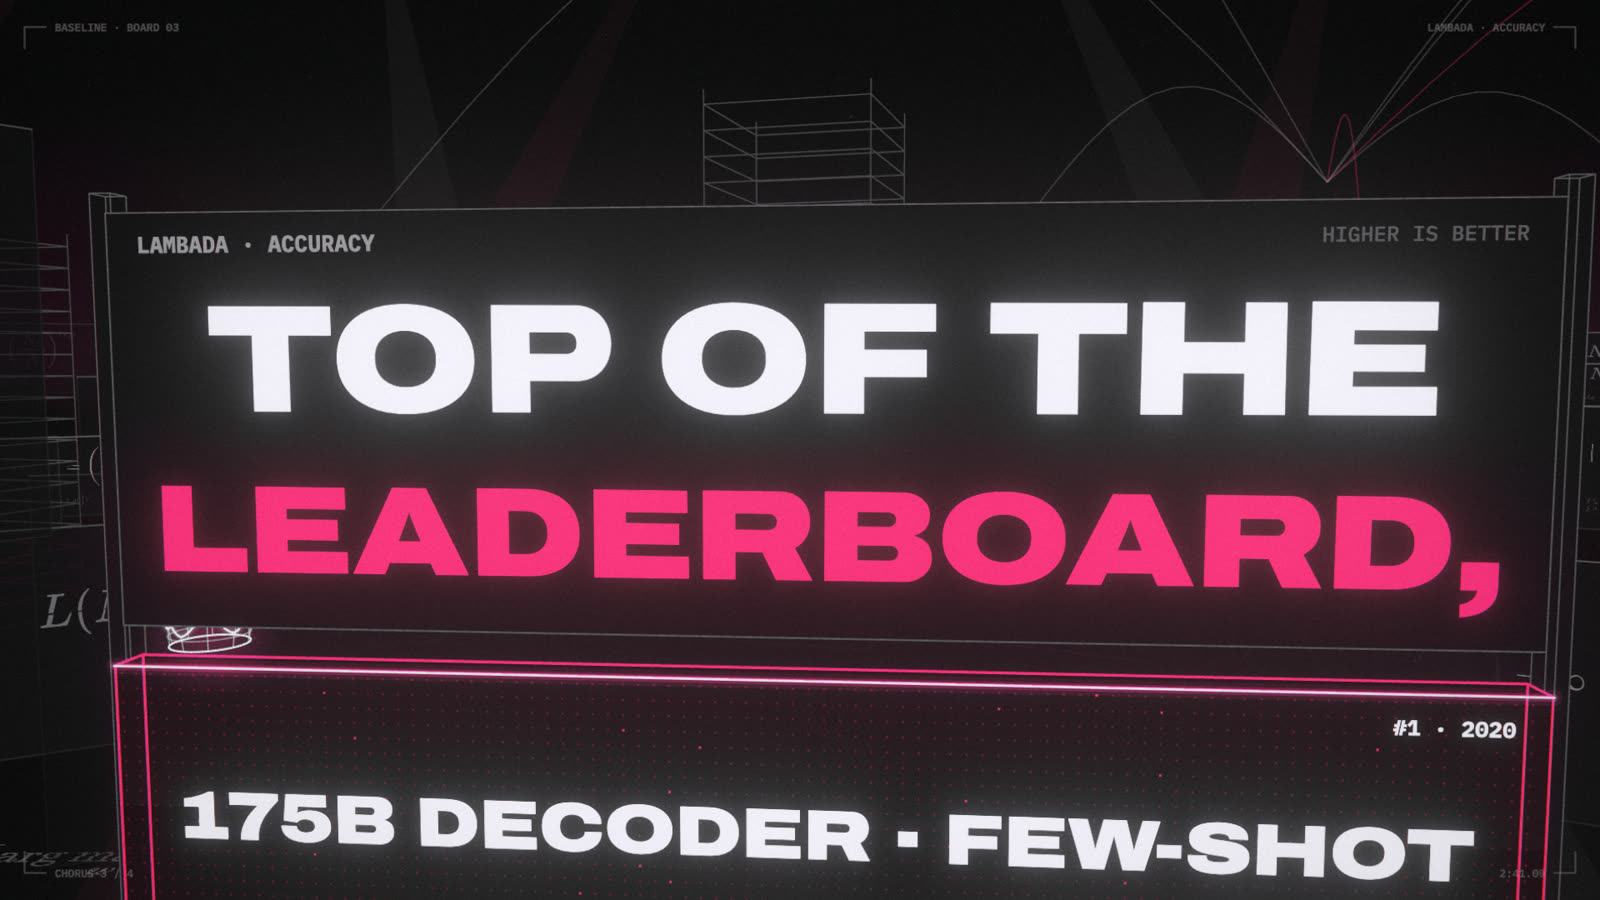

In [2]:
still(161.07)



Qwen/Qwen2.5-0.5B-Instruct: 494M parameters, torch.float32, on mps


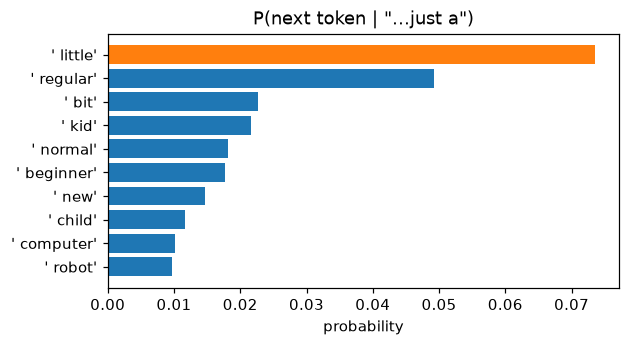

In [3]:
tok, llm = load_llm()
prompt = "You were state of the art, now you're just a"
ids = tok(prompt, return_tensors='pt').to(DEVICE)
with torch.no_grad():
    p = llm(**ids).logits[0, -1].float().softmax(-1)
top = p.topk(10)
fig, ax = plt.subplots(figsize=(6, 3))
labels = [repr(tok.decode([i])) for i in top.indices.tolist()]
ax.barh(labels, top.values.cpu(), color=['C1'] + ['C0'] * 9); ax.invert_yaxis()
ax.set(title=f'P(next token | "…just a")', xlabel='probability');



---

## 4.2 Dense became a mixture: only some experts awake
A dense layer uses every weight for every token. A **mixture of experts** (Shazeer et al., 2017) replaces the MLP with E smaller expert MLPs plus a **router** that sends each token to its top-k experts. You get E× the parameters at about k/E of the compute per token.

Toy version: 8 input clusters, each needing a different function. Can a router with 8 experts and top-2 routing learn to divide the work?



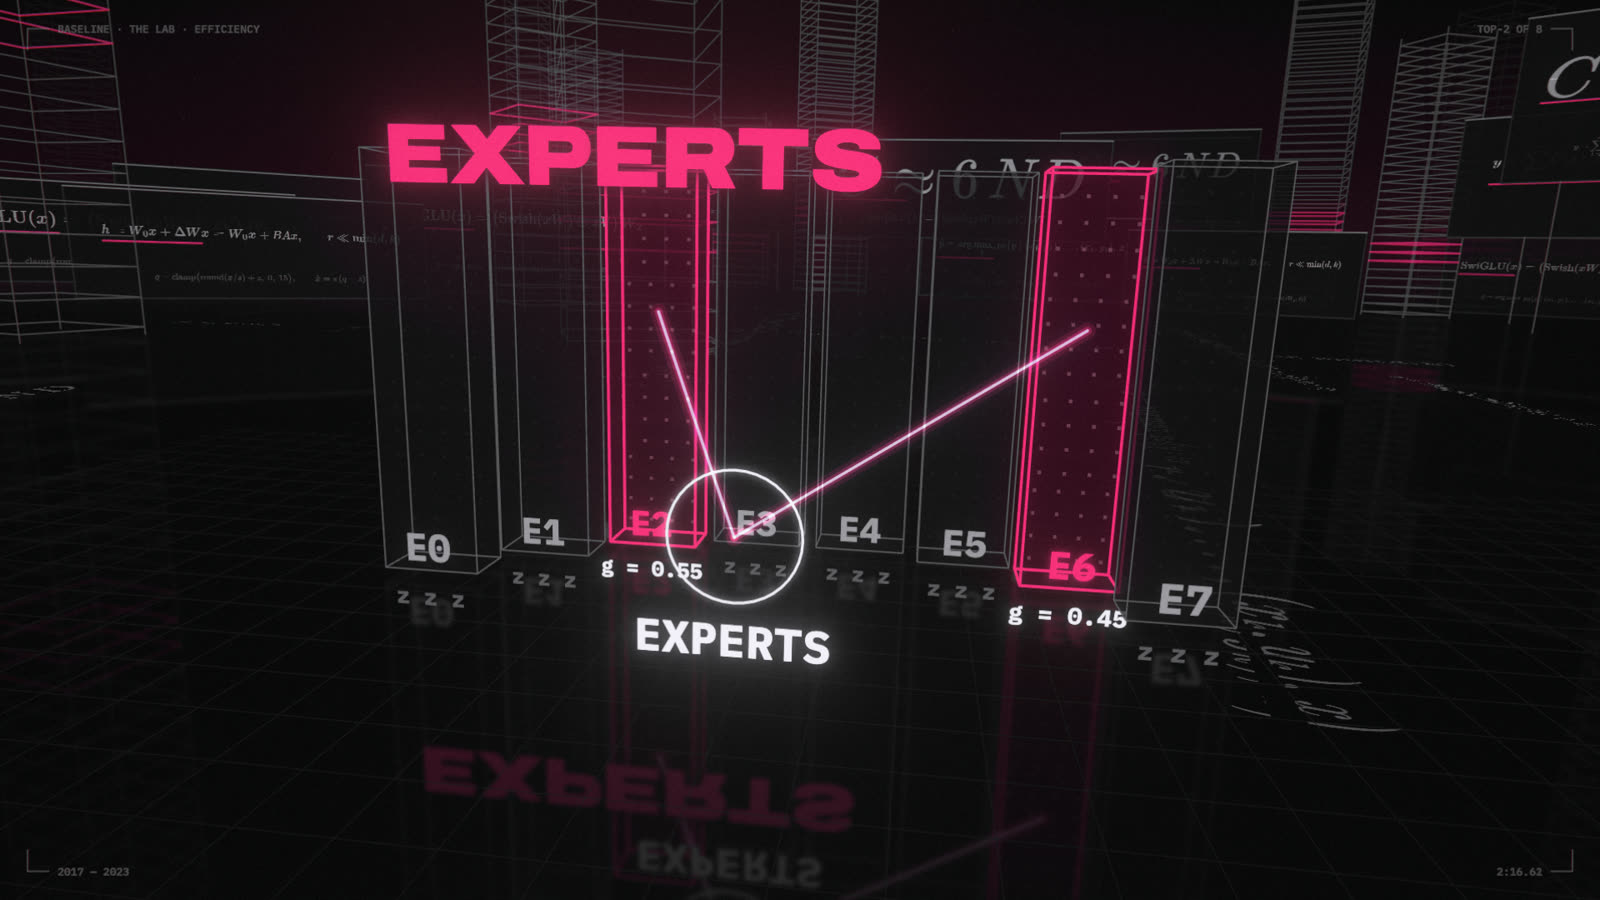

In [4]:
still(136.62)



final MSE 0.666; each token uses 2/8 experts = 25% of expert compute


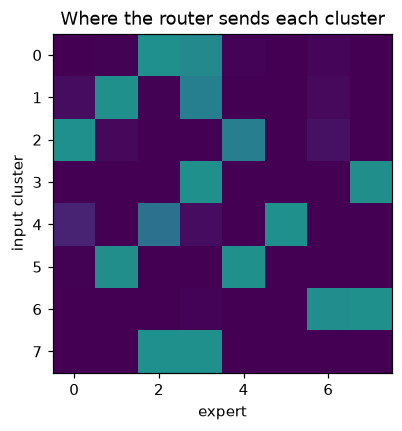

In [5]:
class MoE(nn.Module):
    def __init__(self, d=16, E=8, k=2, hidden=32):
        super().__init__()
        self.k, self.router = k, nn.Linear(d, E)
        self.experts = nn.ModuleList(nn.Sequential(nn.Linear(d, hidden), nn.ReLU(), nn.Linear(hidden, 1)) for _ in range(E))
    def forward(self, x):
        probs = self.router(x).softmax(-1)
        topv, topi = probs.topk(self.k, -1)
        out = torch.zeros(len(x), 1)
        for slot in range(self.k):
            for e, expert in enumerate(self.experts):
                sel = topi[:, slot] == e
                if sel.any():                                   # only routed tokens touch expert e
                    out[sel] += topv[sel, slot, None] * expert(x[sel])
        balance = (probs.mean(0) * F.one_hot(topi[:, 0], len(self.experts)).float().mean(0)).sum() * len(self.experts)
        return out, topi, balance

seed(0)
centers = torch.randn(8, 16) * 3; funcs = torch.randn(8, 16)
def moe_batch(n=512):
    c = torch.randint(0, 8, (n,)); x = centers[c] + torch.randn(n, 16)
    return x, (torch.sin(x * funcs[c]).sum(1, keepdim=True)), c

moe = MoE(); opt = torch.optim.Adam(moe.parameters(), 3e-3)
for step in range(1500):
    x, y, _ = moe_batch(); out, _, bal = moe(x)
    loss = F.mse_loss(out, y) + 0.01 * bal                     # + load-balancing loss keeps all experts in use
    opt.zero_grad(); loss.backward(); opt.step()
x, y, c = moe_batch(4000); _, topi, _ = moe(x)
routing = torch.zeros(8, 8)
for ci in range(8):
    routing[ci] = torch.bincount(topi[c == ci].flatten(), minlength=8).float() / (2 * (c == ci).sum())
fig, ax = plt.subplots(figsize=(4.4, 4)); ax.imshow(routing, vmin=0, vmax=1); ax.grid(False)
ax.set(xlabel='expert', ylabel='input cluster', title='Where the router sends each cluster')
print(f'final MSE {F.mse_loss(moe(x)[0], y).item():.3f}; each token uses 2/8 experts = 25% of expert compute')



The router learned a division of labor on its own: each cluster goes mostly to a couple of experts. Without the load-balancing term, routers tend to collapse onto a few favorite experts. Try `0 * bal`.



---

## 4.3 32 bits down to 4, for the throughput's sake
Each parameter is a 32-bit (or 16-bit) float. LLM inference is mostly limited by **memory bandwidth**: generating each token streams every weight from memory once. Store each weight in 4 bits and you move 8× less data, and the model fits on smaller machines.

**Quantization** maps each row of a weight matrix onto 16 evenly spaced levels: q = round(w / scale), clipped to [−8, 7], with scale = max|w| / 7 per row. Below we quantize every linear layer of the real LLM and measure the damage as **perplexity** (e^loss, lower is better) on a passage it hasn't seen.



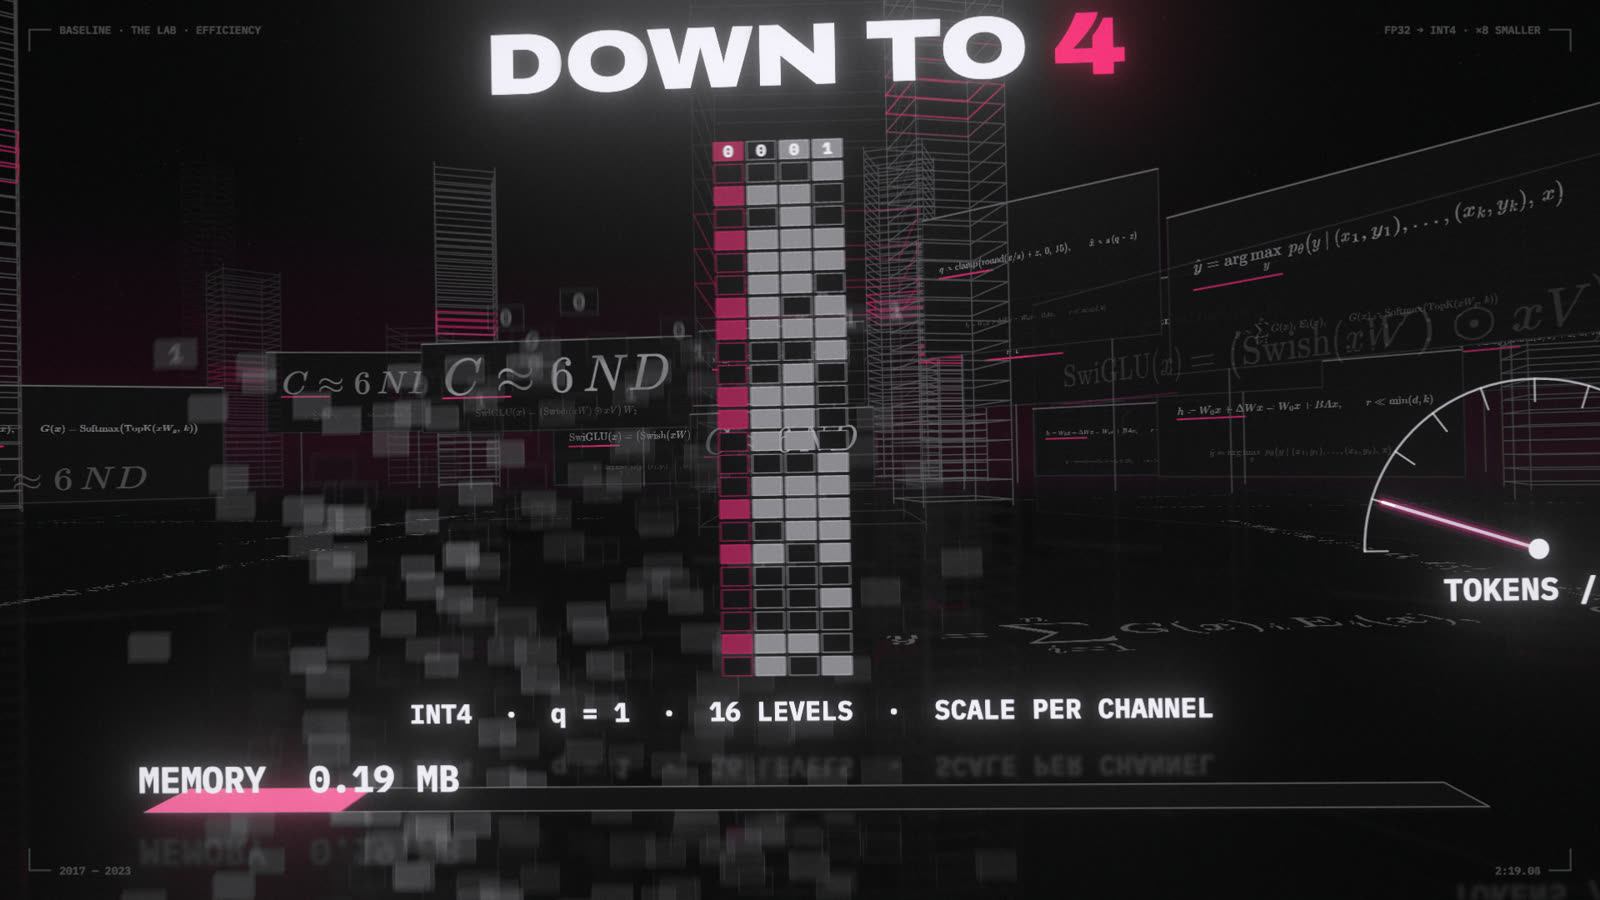

In [6]:
still(139.05)



### Your turn: quantize in groups
Write quantize-then-dequantize with one scale per group of `group` consecutive weights: reshape to (−1, group), take each group's largest |w| as its scale (divided by the top integer level, 7 for 4 bits), round w/scale to an integer in [−8, 7], multiply back. The check plants one big outlier and makes sure the *other* group in that row keeps its precision.



In [7]:
def quantize_groups(w, bits, group):
    """w: a 2-D tensor whose row length is a multiple of group. Return the dequantized tensor, same shape."""
    raise NotImplementedError        # your code here: about 4 lines

check('quantize_groups', quantize_groups)



⏳ quantize_groups: not attempted yet. Fill in the code above and rerun this cell. (Stuck? The reference solution is in notebooks/exercises.py.)


Now the real thing, on every linear layer of the LLM. Perplexity is e^loss (§2.1): roughly how many tokens the model is "choosing between" at each step, so lower is better.

> **Predict first.** Rank these by how much they hurt perplexity: INT8 per row, INT4 per row, INT4 with groups of 128, INT3 with groups of 128.



In [8]:
passage = shakespeare()[-6000:]
eval_ids = tok(passage, return_tensors='pt')['input_ids'][:, :1024].to(DEVICE)

@torch.no_grad()
def perplexity(model):
    return math.exp(model(eval_ids, labels=eval_ids).loss.item())

linears = [m for n, m in llm.named_modules() if isinstance(m, nn.Linear) and 'lm_head' not in n]
originals = [m.weight.data.to('cpu', copy=True) for m in linears]

def fake_quant(w, bits, group=None):
    """Quantize w to signed `bits`-bit integers with one scale per row (or per group of columns), then dequantize."""
    shape = w.shape; w = w.float()
    if group:
        w = w.reshape(-1, group)
    qmax = 2 ** (bits - 1) - 1
    scale = w.abs().amax(-1, keepdim=True).clamp(min=1e-8) / qmax
    return ((w / scale).round().clamp(-qmax - 1, qmax) * scale).reshape(shape)

results = {'original': perplexity(llm)}
for label, bits, group in [('INT8 per-row', 8, None), ('INT4 per-row', 4, None), ('INT4 group-128', 4, 128), ('INT3 group-128', 3, 128)]:
    for m, w in zip(linears, originals):
        m.weight.data = fake_quant(w.to(DEVICE), bits, group).to(m.weight.dtype)
    results[label] = perplexity(llm)
for m, w in zip(linears, originals):
    m.weight.data = w.to(DEVICE, m.weight.dtype)
del originals

n_lin = sum(m.weight.numel() for m in linears)
orig_bits = next(llm.parameters()).element_size() * 8
for k, v in results.items():
    bits = orig_bits if 'orig' in k else int(k[3])
    print(f'{k:>22}: perplexity {v:7.2f}   linear weights ≈ {n_lin * bits / 8 / 2**20:,.0f} MB at {bits} bits')



              original: perplexity   39.77   linear weights ≈ 1,365 MB at 32 bits
          INT8 per-row: perplexity   39.69   linear weights ≈ 341 MB at 8 bits
          INT4 per-row: perplexity   93.59   linear weights ≈ 171 MB at 4 bits
        INT4 group-128: perplexity   55.68   linear weights ≈ 171 MB at 4 bits
        INT3 group-128: perplexity  671.17   linear weights ≈ 128 MB at 3 bits


INT8 is nearly free. INT4 per row hurts, because one outlier weight sets the scale for the whole row and crushes everything else into a few levels. Give every **group of 128** weights its own scale and most of the quality comes back for about 3% more storage. That's the core idea behind practical 4-bit formats (GPTQ, AWQ, GGUF's Q4_K, MLX 4-bit). On the `cuda` tier you can compare real 4-bit kernels with `bitsandbytes`.



---

## 4.4 Full fine-tune → LoRA: a low-rank little patch
**Fine-tuning** continues training a pretrained model on your own data. Updating all its weights means storing a full copy of the model per task, plus optimizer state 2–3× its size. **LoRA** (Hu et al., 2021) freezes W and learns a low-rank update ΔW = B·A, where A is r × d and B is d × r with r ≈ 8. Only B and A are trained. That's under 1% of the parameters, and the patch is a few MB.

`add_lora` in `blcourse.py` wraps the attention's `q_proj` and `v_proj` layers. Task: teach the model the film's house style for "baseline cards", a format it has never seen.



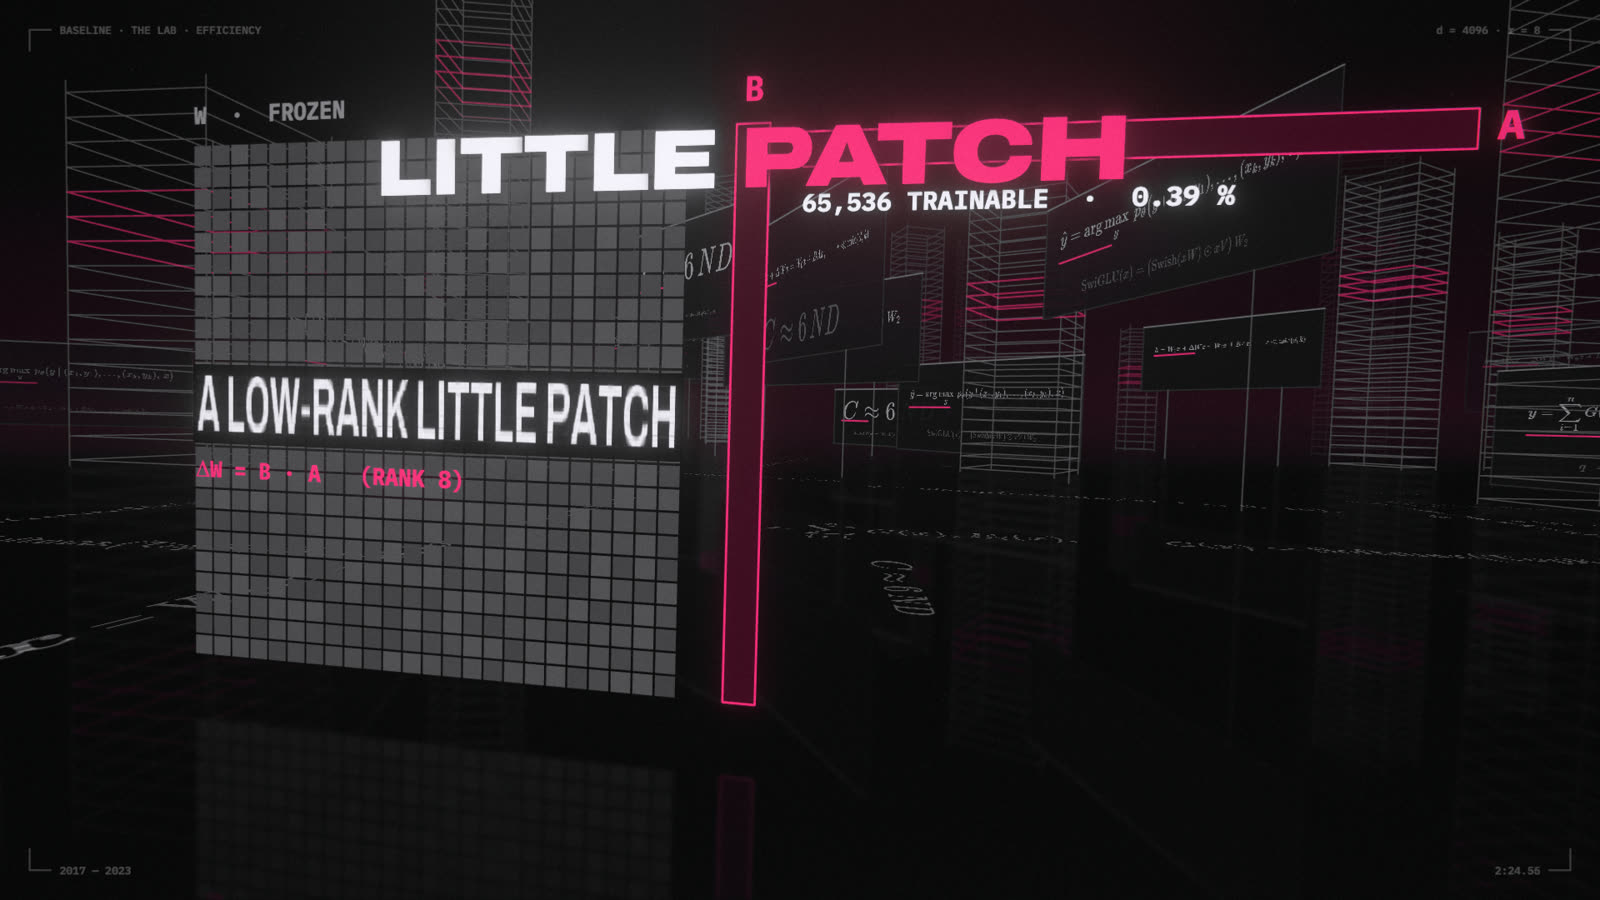

In [9]:
still(144.56)



In [10]:
CARDS = [
    ('Perceptron', 'PERCEPTRON · 1958 · ROSENBLATT · BEATEN BY: MULTI-LAYER NETS'),
    ('SVM', 'SVM · 1995 · CORTES & VAPNIK · BEATEN BY: DEEP CNNS'),
    ('AlexNet', 'ALEXNET · 2012 · KRIZHEVSKY ET AL. · BEATEN BY: DEEPER CNNS'),
    ('ResNet', 'RESNET · 2015 · HE ET AL. · BEATEN BY: VISION TRANSFORMERS'),
    ('LSTM', 'LSTM · 1997 · HOCHREITER & SCHMIDHUBER · BEATEN BY: TRANSFORMERS'),
    ('Seq2seq', 'SEQ2SEQ · 2014 · SUTSKEVER ET AL. · BEATEN BY: ATTENTION'),
    ('GAN', 'GAN · 2014 · GOODFELLOW ET AL. · BEATEN BY: DIFFUSION'),
    ('BERT', 'BERT · 2018 · DEVLIN ET AL. · BEATEN BY: DECODER-ONLY LLMS'),
    ('Word2vec', 'WORD2VEC · 2013 · MIKOLOV ET AL. · BEATEN BY: CONTEXTUAL EMBEDDINGS'),
    ('Dropout', 'DROPOUT · 2014 · SRIVASTAVA ET AL. · BEATEN BY: MORE DATA'),
    ('Batch normalization', 'BATCH NORMALIZATION · 2015 · IOFFE & SZEGEDY · BEATEN BY: LAYER NORMALIZATION'),
    ('GRU', 'GRU · 2014 · CHO ET AL. · BEATEN BY: TRANSFORMERS'),
    ('VGG', 'VGG · 2014 · SIMONYAN & ZISSERMAN · BEATEN BY: RESNET'),
    ('Adam', 'ADAM · 2014 · KINGMA & BA · BEATEN BY: ADAMW'),
    ('GPT-2', 'GPT-2 · 2019 · RADFORD ET AL. · BEATEN BY: GPT-3'),
    ('Variational autoencoder', 'VARIATIONAL AUTOENCODER · 2013 · KINGMA & WELLING · BEATEN BY: DIFFUSION'),
]
HELD_OUT = ['Transformer', 'Random forest', 'Hidden Markov model', 'U-Net']
Q = 'Baseline card: {}'

print('BEFORE (zero-shot):')
for name in HELD_OUT[:2]:
    print(f'  {name}: {chat(tok, llm, Q.format(name), 40)[:110]!r}')



BEFORE (zero-shot):


  Transformer: 'Transformer is a type of deep learning model that has been widely used in natural language processing (NLP) an'


  Random forest: 'The Baseline Card for a Random Forest model is typically used to describe the performance of a random forest a'


### Your turn: count the patch
LoRA adds two thin matrices to a weight of shape (d_out, d_in): A is (r, d_in) and B is (d_out, r). How many numbers does that add? Write it, then compare with a full fine-tune of the same matrix (d_out × d_in).



In [11]:
def lora_params(d_out, d_in, r):
    """The number of trainable numbers LoRA adds to one d_out × d_in weight matrix at rank r."""
    raise NotImplementedError        # your code here: one line

check('lora_params', lora_params)



⏳ lora_params: not attempted yet. Fill in the code above and rerun this cell. (Stuck? The reference solution is in notebooks/exercises.py.)


> **Predict first.** After training on 16 cards, the model sees techniques it never saw. Will it get the *format* right? Will it get the *years and authors* right?



trainable: 540,672 of 494,573,440 = 0.109%


LoRA fine-tune: 34.18s


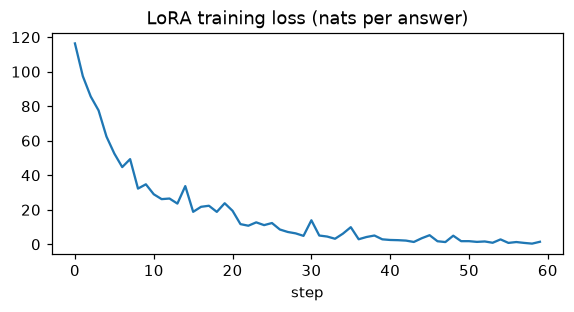

In [12]:
lora_layers = add_lora(llm, r=8)
trainable = [p for p in llm.parameters() if p.requires_grad]
print(f'trainable: {sum(p.numel() for p in trainable):,} of {n_params(llm):,} = {sum(p.numel() for p in trainable) / n_params(llm):.3%}')
opt = torch.optim.AdamW(trainable, lr=1e-3)
seed(0); losses = []
with timer('LoRA fine-tune:'):
    for step in range(CFG['lora_steps']):
        batch = [CARDS[i] for i in torch.randint(0, len(CARDS), (4,)).tolist()]
        loss = 0
        for name, card in batch:
            ids, n = chat_ids(tok, Q.format(name), card)
            loss = loss - answer_logprob(llm, ids, n).mean() / len(batch)
        opt.zero_grad(); loss.backward(); opt.step(); losses.append(loss.item())
fig, ax = plt.subplots(figsize=(6, 2.6)); ax.plot(losses); ax.set(title='LoRA training loss (nats per answer)', xlabel='step');



In [13]:
print('AFTER LoRA, on techniques it never saw in training:')
for name in HELD_OUT:
    print(f'  {name:>20}: {chat(tok, llm, Q.format(name), 40)}')



AFTER LoRA, on techniques it never saw in training:


           Transformer: TRANSFORMER · 2019 · MIKOLOV ET AL. · BEATEN BY: TRANSFORMERS


         Random forest: RANDOM FOREST · 1986 · HOCHMAN · BEATEN BY: DEEPER CNNS


   Hidden Markov model: HIDDEN MARKOV MODEL · 1953 · ROSENBLATT · BEATEN BY: STATE TRANSFORMERS


                 U-Net: U-NET · 2015 · GOODFELLOW ET AL. · BEATEN BY: VISION TRANSFORMERS


The format transferred to techniques that weren't in the 16 examples, and the model fills in the year and authors from what it already knew. The facts can still be wrong, and a small model is often confidently wrong. **LoRA teaches form far more reliably than knowledge.** In real projects, it's the right tool for style, format and tone, and a poor way to add facts. For facts, put them in the prompt (next section) or use retrieval.



---

## 4.5 Then just prompt it in context: no gradient to catch
GPT-3 (2020) showed that a big enough model can pick up a task from a few examples placed in its prompt, with no training at all. This is **in-context learning**. Let's turn the LoRA patch off and try that instead. For a chat model, the examples go in as earlier turns of the conversation.



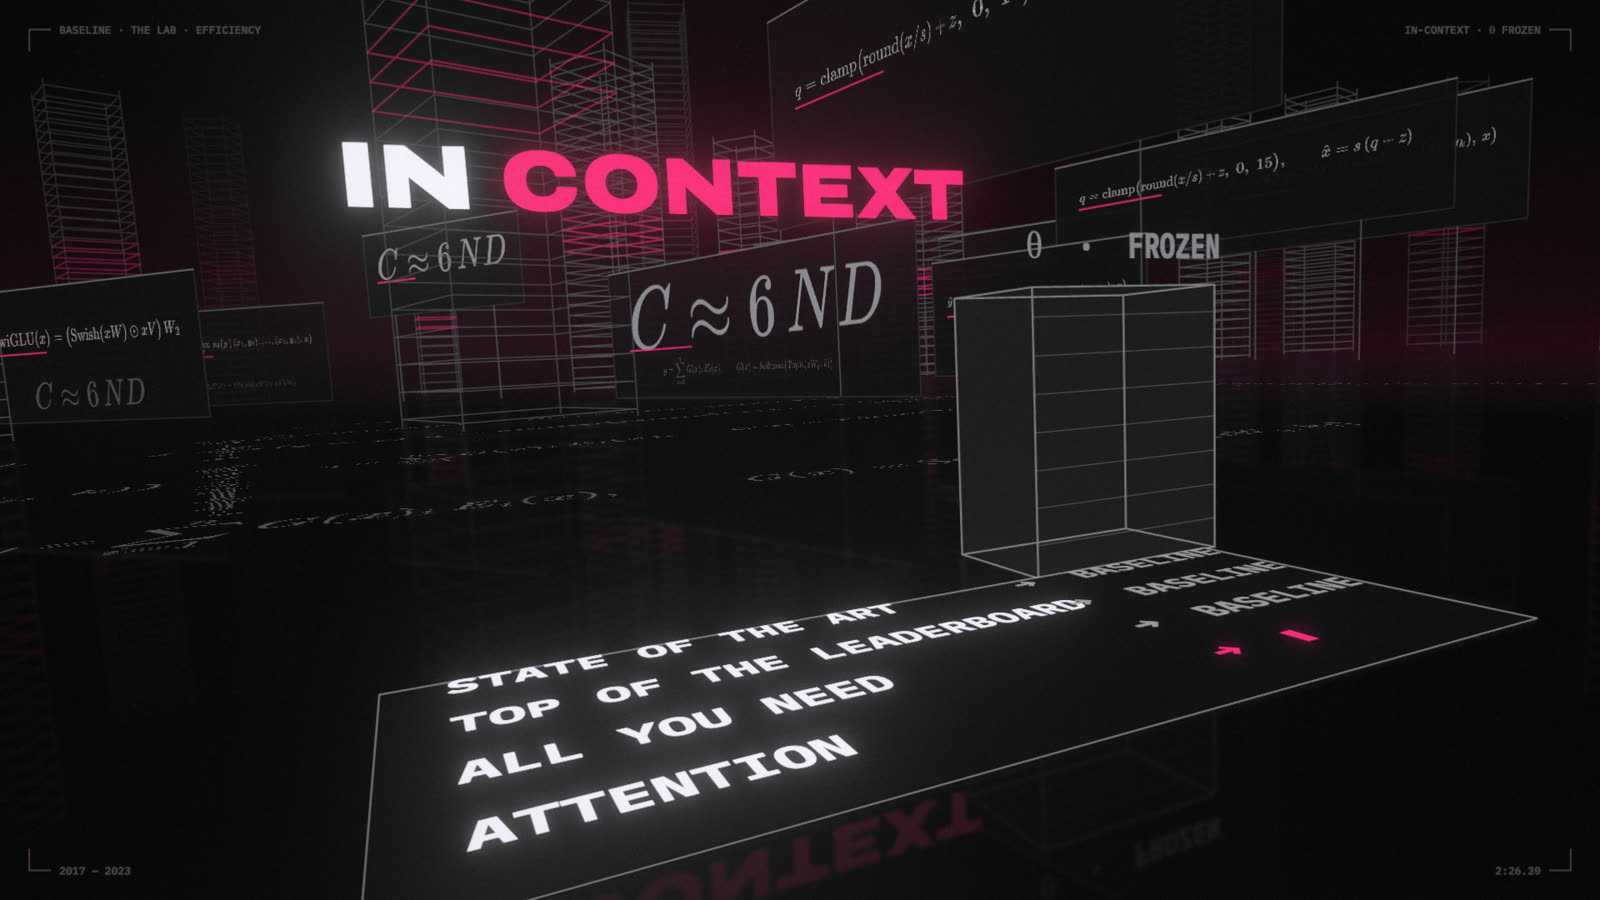

In [14]:
still(146.3)



In [15]:
few_shot = [(Q.format(n), c) for n, c in CARDS[:5]]       # five examples, as earlier turns of the conversation
with lora_disabled(lora_layers):
    for name in HELD_OUT:
        print(f'  {name:>20}: {chat(tok, llm, Q.format(name), 40, history=few_shot)}')



           Transformer: TRANSFORMER · 2017 · BERT et al. · BEATEN BY: MACHINE LEARNING AND RECOGNITION SYSTEMS


         Random forest: RANDOM FOREST · 1967 · BERNARD · BEATEN BY: MACHINE LEARNING


   Hidden Markov model: HMM · 1967 · HAMMING · BEATEN BY: MACHINE LEARNING


                 U-Net: U-Net · 2016 · ZHANG et al. · BEATEN BY: TRANSFORMERS


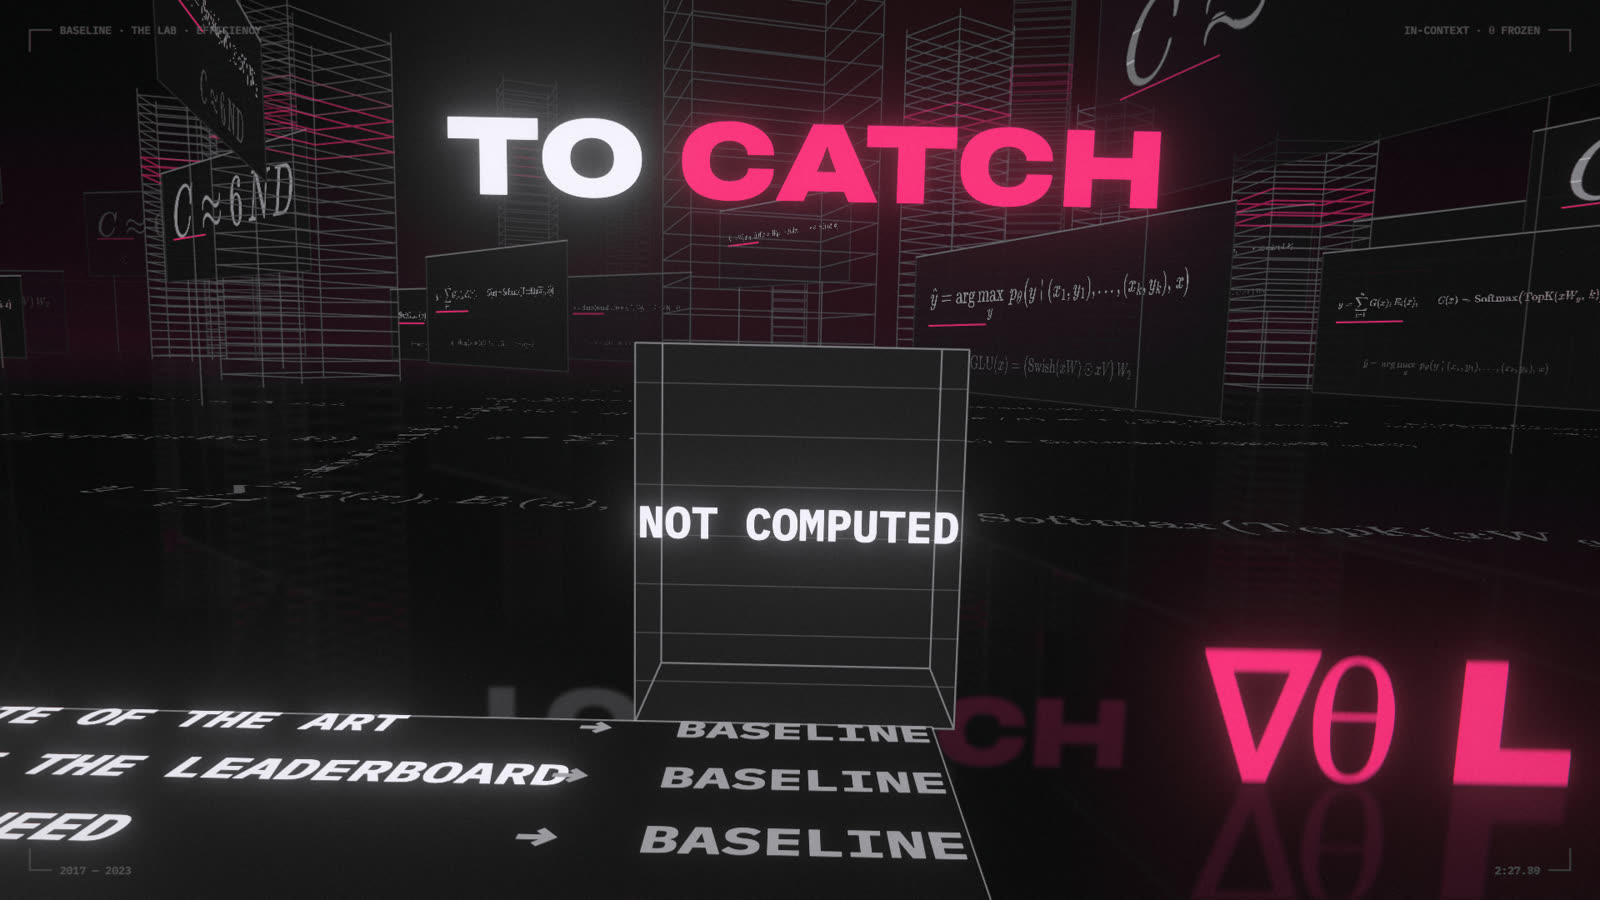

In [16]:
still(147.8)



**Developer's rule of thumb:** try prompting first, since it costs nothing and you can change it at any time. Fine-tune with LoRA when the prompt gets too long, too expensive, or too unreliable, or when you need a behavior that's hard to describe with examples.



---

## 4.6 RLHF trained a reward model to rank
A pretrained LLM continues text. That's not the same as being helpful. **RLHF** (Christiano 2017; InstructGPT 2022) adds three steps:

1. **SFT**: fine-tune on human-written example answers (what you did with LoRA in §4.4).
2. **Reward model**: humans compare pairs of answers ("A is better than B"), and a model learns to score answers so that the scores predict those preferences.
3. **RL (PPO)**: optimize the LLM to maximize the reward model's score, with a penalty for drifting too far from the SFT model.

Step 2 rests on the **Bradley–Terry** model of comparisons: P(A ≻ B) = σ(r_A − r_B). Below, four answers have hidden "true" quality. We simulate 300 noisy human votes and recover the scores from the votes alone.



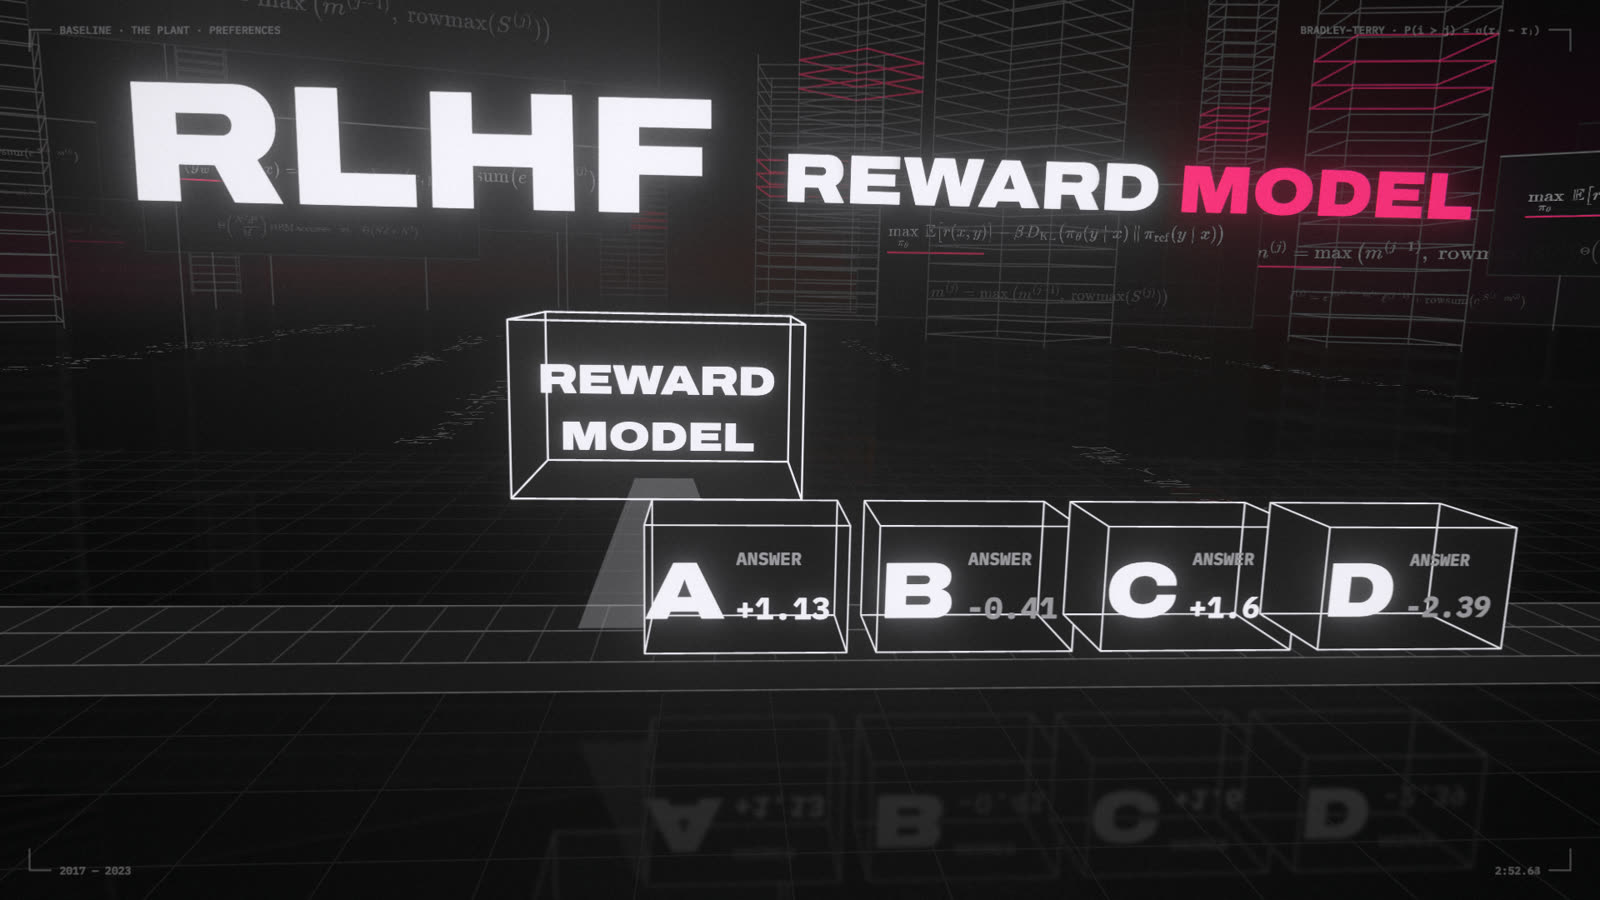

In [17]:
still(172.64)



In [18]:
seed(0)
true_r = torch.tensor([1.1, 0.2, 1.9, -0.8])                      # answers A, B, C, D
pairs = torch.randint(0, 4, (600, 2)); pairs = pairs[pairs[:, 0] != pairs[:, 1]][:300]
p_first = torch.sigmoid(true_r[pairs[:, 0]] - true_r[pairs[:, 1]])
first_wins = torch.rand(len(pairs)) < p_first                     # noisy human labels

r = torch.zeros(4, requires_grad=True); opt = torch.optim.Adam([r], 0.05)
for _ in range(500):
    margin = r[pairs[:, 0]] - r[pairs[:, 1]]
    loss = F.binary_cross_entropy_with_logits(margin, first_wins.float())   # Bradley–Terry likelihood
    opt.zero_grad(); loss.backward(); opt.step()
fitted = (r - r.mean()).detach(); truth = true_r - true_r.mean()
for name, t, f_ in zip('ABCD', truth, fitted):
    print(f'answer {name}: true {t:+.2f}   fitted from votes {f_:+.2f}')
print('ranking:', ' ≻ '.join('ABCD'[i] for i in fitted.argsort(descending=True)))



answer A: true +0.50   fitted from votes +0.35
answer B: true -0.40   fitted from votes -0.36
answer C: true +1.30   fitted from votes +1.00
answer D: true -1.40   fitted from votes -1.00
ranking: C ≻ A ≻ B ≻ D


---

## 4.7 DPO skipped the middleman
RLHF's step 3 is the fiddly one: an RL loop, a separate reward model held in memory, and a lot of tuning. **DPO** (Rafailov et al., 2023) shows that, for the KL-constrained objective RLHF optimizes, the best policy has a closed form. Substituting it back into the Bradley–Terry likelihood cancels the intractable normalizer Z(x), and leaves a plain supervised loss on preference pairs (y_w preferred over y_l):

$$L_\text{DPO} = -\log\sigma\Big(\beta\big[\log\tfrac{\pi_\theta(y_w|x)}{\pi_\text{ref}(y_w|x)} - \log\tfrac{\pi_\theta(y_l|x)}{\pi_\text{ref}(y_l|x)}\big]\Big)$$

No reward model and no RL loop. You need two forward passes per pair, through the model being trained (π_θ) and through a frozen copy (π_ref). With LoRA the frozen copy is free: it's the same model with the patch turned off (`lora_disabled`).

Our preference: **short, direct answers.** For each question, the *chosen* answer is one sentence we wrote. The *rejected* answer is whatever the model itself says now. That's how real preference data works: you compare against the model's own outputs, so it learns to move away from what it actually does.



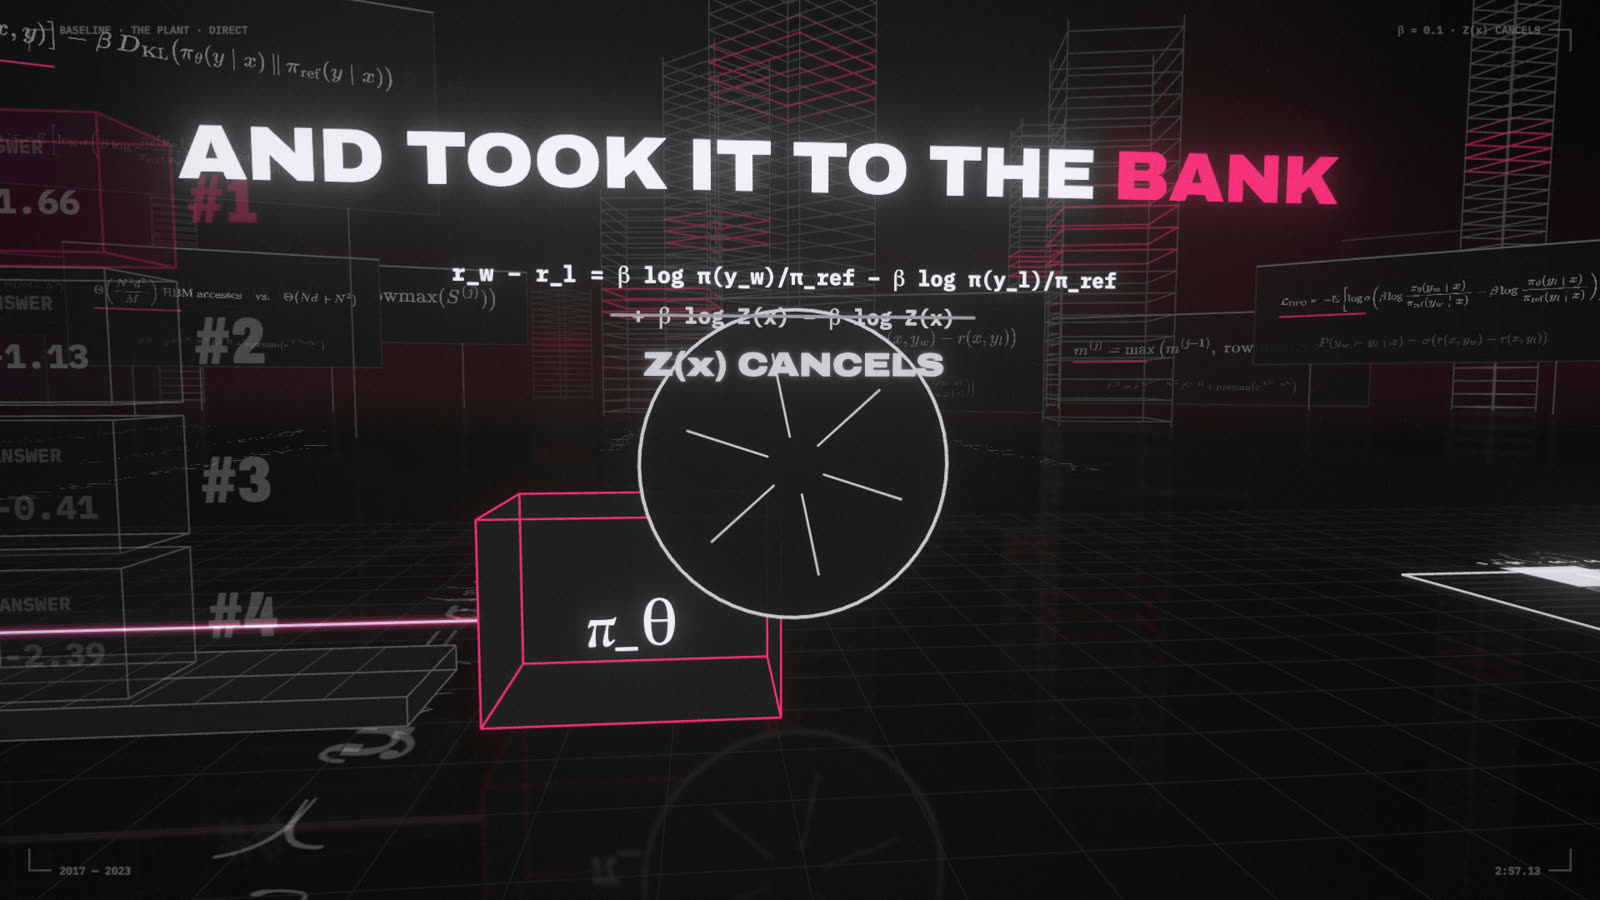

In [19]:
still(177.13)



In [20]:
PREFS = [                                  # (question, the short answer we prefer)
    ('What is overfitting?', 'When a model memorizes its training data instead of learning patterns that generalize.'),
    ('What is a learning rate?', 'The step size gradient descent takes when updating the weights.'),
    ('What does a GPU do for deep learning?', 'It runs the many matrix multiplications of training and inference in parallel.'),
    ('What is a token?', 'A chunk of text, often part of a word, that the model reads as one integer.'),
    ('What is a loss function?', 'A number that measures how wrong the model is; training minimizes it.'),
    ('What is an embedding?', 'A learned vector that represents a token or item so that similar things are close.'),
    ('What is a validation set?', 'Held-out data used to choose settings, kept separate from the final test set.'),
    ('What is fine-tuning?', 'Continuing to train a pretrained model on your own, smaller dataset.'),
    ('What is attention?', 'A weighted average over all positions, with weights from query–key similarity.'),
    ('What is quantization?', 'Storing weights in fewer bits, like 4 instead of 16, to save memory and time.'),
    ('What is a GAN?', 'Two networks, a generator and a discriminator, trained against each other.'),
    ('What is a benchmark?', 'A fixed public test set and metric that models are compared on.'),
]
HELD = ['What is backpropagation?', 'What is a context window?', 'What is a mixture of experts?', 'What is dropout?']

reset_lora(lora_layers)          # start DPO from the base model: zero the format-card patch from §4.4
def answers(tag):
    out = {q: chat(tok, llm, q, 120) for q in HELD}
    print(f'{tag}: mean {np.mean([len(a.split()) for a in out.values()]):.0f} words')
    for q, a in out.items():
        print(f'  {q}\n    {a[:200]}')
    return out
before = answers('BEFORE DPO')
own = {q: chat(tok, llm, q, 120) for q, _ in PREFS}         # the rejected side: the model's current answers



BEFORE DPO: mean 102 words
  What is backpropagation?
    Backpropagation is an algorithm used in machine learning to train neural networks. It's particularly useful for training deep neural networks like convolutional neural networks (CNNs) and recurrent ne
  What is a context window?
    A context window in the context of AI and machine learning refers to a portion of data that is used for training models or analyzing patterns within a larger dataset. It's typically a small segment of
  What is a mixture of experts?
    A mixture of experts refers to a group of individuals who have expertise in different areas or fields and work together to solve complex problems. This approach can be effective when dealing with inte
  What is dropout?
    Dropout is an optimization technique used in machine learning to prevent overfitting. It works by randomly dropping out some of the training examples during training time. This means that instead of u


### Your turn: the DPO loss for one pair
Inputs are four log-probabilities of whole answers: the chosen (w) and rejected (l) answer, under the model being trained (pol) and the frozen reference (ref). The loss is −log σ(β · [(pol_w − ref_w) − (pol_l − ref_l)]). Before any training the policy equals the reference, so what should the loss be? The check tests that, and that moving toward the chosen answer lowers the loss.



In [21]:
def dpo_loss(pol_w, pol_l, ref_w, ref_l, beta):
    """All inputs are plain numbers. Return the DPO loss (a number)."""
    raise NotImplementedError        # your code here: 2 lines

check('dpo_loss', dpo_loss)



⏳ dpo_loss: not attempted yet. Fill in the code above and rerun this cell. (Stuck? The reference solution is in notebooks/exercises.py.)


> **Predict first.** The model's answers above average about 100 words. After 40 DPO steps on 12 pairs, what will the average be on the four held-out questions?



DPO: 21.13s


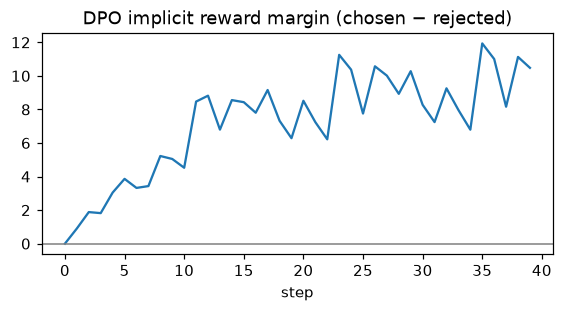

In [22]:
opt = torch.optim.AdamW([p for p in llm.parameters() if p.requires_grad], lr=2e-4)
beta, log = 0.1, []
seed(0)
with timer('DPO:'):
    for step in range(CFG['dpo_steps']):
        q, good = PREFS[step % len(PREFS)]
        ids_w, n = chat_ids(tok, q, good); ids_l, _ = chat_ids(tok, q, own[q])
        with torch.no_grad(), lora_disabled(lora_layers):                    # π_ref: the model without the patch
            ref_w, ref_l = answer_logprob(llm, ids_w, n), answer_logprob(llm, ids_l, n)
        pol_w, pol_l = answer_logprob(llm, ids_w, n), answer_logprob(llm, ids_l, n)
        margin = beta * ((pol_w - ref_w) - (pol_l - ref_l))                   # implicit reward difference
        loss = -F.logsigmoid(margin).mean()
        opt.zero_grad(); loss.backward(); opt.step()
        log.append((loss.item(), margin.item()))
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.plot([m for _, m in log]); ax.axhline(0, c='gray', lw=1)
ax.set(title='DPO implicit reward margin (chosen − rejected)', xlabel='step');



In [23]:
after = answers('AFTER DPO')



AFTER DPO: mean 40 words
  What is backpropagation?
    Backpropagation is an algorithm used to train neural networks. Backpropagation is the process of calculating the error between the output and target values for each layer in a neural network. The erro
  What is a context window?
    The Context Window is the area of the screen that displays the current state of the system and the user's actions. It can be used to display information about the system or the user's actions in real 
  What is a mixture of experts?
    A mixture of experts refers to the combination of multiple experts in a specific field. This type of expert can be used for solving complex problems and making decisions.
The mixture of experts method
  What is dropout?
    The Dropout mechanism in the LSTM model is used to prevent overfitting of the network. The dropout mechanism randomly sets some neurons to be dropped out during training and testing.


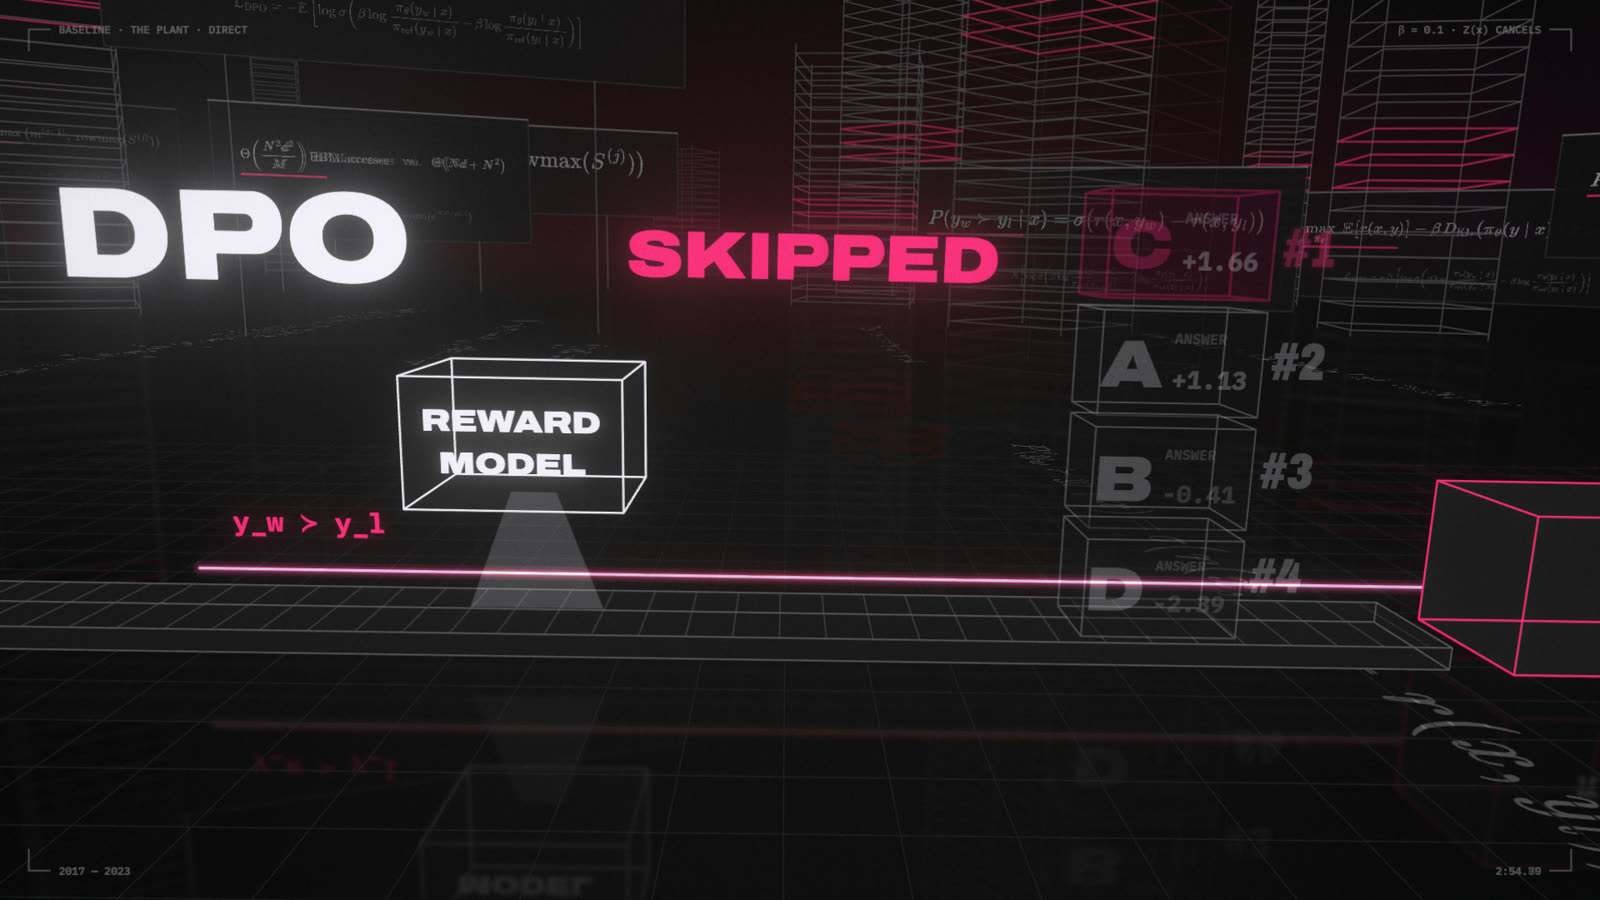

In [24]:
still(174.8)



A dozen preference pairs and a few dozen steps on a laptop visibly shorten the model's answers to questions it never saw. Shorter isn't the same as correct, though: a 0.5B model's facts are still shaky.

### Try it
Rerun the DPO cells with `lr=5e-4`. The margin climbs higher, and the answers get shorter still, then stop making sense. The model has **over-optimized** the preference and drifted far from what it knew. That's why RLHF penalizes drift from the reference model, and why β and the step budget matter. A preference signal tells the model which direction to move, not how far.

This is how the "personality" of chat models is shaped, with far more data and far more care. Notice also how *easy* it would be to teach a bad preference. Alignment data is a design decision, not a detail.



---

### Checkpoint
1. What does an LLM output at each step, and how does that become text?
2. Why does a mixture of experts have many more parameters than it uses per token?
3. A 7B model takes about 14 GB at 16 bits. About how much at INT4 with group scales, and why do group scales help?
4. LoRA with r = 8 on a 4096 × 4096 matrix: how many trainable numbers, versus a full fine-tune of that matrix?
5. When would you choose LoRA over a few-shot prompt, and when not?
6. What does a reward model learn from "A beat B" comparisons, and why doesn't DPO need one?

<details><summary>Answers</summary>

1. A score (logit) for every token in its vocabulary. Softmax turns them into probabilities, one token is picked (sampled, or the top one), appended, and the model runs again.
2. A router sends each token to only a few of the experts (top-2 of 8 in the lab), so most expert weights sit idle for any given token. You get the capacity of all of them for the compute of a few.
3. About 14 × 4/16 ≈ 3.5 GB, plus a few percent for the scales. With one scale per group, a single outlier only coarsens its own group of 128 instead of the whole row.
4. 2 × 8 × 4096 = 65,536, versus 16,777,216 for the full matrix: 0.39%.
5. Prompt first: it's free to change and needs no training. LoRA when the prompt gets too long or costly per request, or when you need a consistent style or format the model won't follow from examples. Neither is a good way to add facts; put facts in the prompt or use retrieval.
6. It learns a score per answer such that σ(score_A − score_B) predicts how often people prefer A (Bradley–Terry). DPO shows that, for the objective RLHF optimizes, the policy itself defines that score (via its log-probability relative to the reference), so you can train on the comparisons directly.
</details>

**Next:** Module 5, scale and long context.